# 모듈 2 · NLP 미니프로젝트 — BERT 기반 한국어 의미 검색 시스템 개발 및 성능 비교

**기간:** 2일·총 16교시 · **체크포인트:** Day 1 `CP-01~06`, Day 2 `CP-07~10`  
**검색 모델:** TF-IDF · `klue/bert-base` · 한국어 Sentence-BERT  
**최종 결과물:** `search_docs()` + 검색 성능 보고서 + 기술적 의사결정 기록(ADR)

> 이 프로젝트는 GPT로 답변을 생성하거나 BERT를 재학습하는 프로젝트가 아닙니다. **문서의 표현 → 유사도 계산 → Top-k 검색 → 정답 평가 → 오류 분석 → 최종 검색 방식 선정**을 직접 개발합니다.
>
> **학생용 안내:** `[학생 구현]` 셀의 `TODO`를 작성하고 `raise NotImplementedError(...)`를 지운 뒤 `[공통 검증]` 셀을 실행하세요. `[기록]`으로 표시된 Markdown 셀은 실제 결과를 보고 직접 작성합니다. `생각해 볼 질문`은 별도 제출이 아닙니다.


## 00. 환경 설치와 세션 초기화 복구

GPU 세션이 초기화되더라도 첫 코드 셀부터 다시 실행할 수 있도록 구성했습니다. 패키지·모델 가중치·데이터가 없는 경우 자동으로 준비하며, 이미 저장된 파일은 재사용합니다.


**환경 설치(공통).** 필요한 Python 패키지를 한 번에 점검하고 누락되거나 호환 범위를 벗어난 패키지만 설치합니다. GPU 이미지에 이미 설치된 CUDA용 PyTorch는 가능한 한 유지하며, 설치 후 CUDA 상태를 확인합니다.


In [1]:
# [공통] 00-1 — 필요한 패키지 자동 설치
import sys, subprocess, importlib.metadata as im
from importlib.util import find_spec

# Python 패키지가 GPU 세션 초기화로 사라진 경우에도 첫 셀부터 복구합니다.
# RunPod GPU 이미지의 PyTorch/CUDA 조합은 가능하면 변경하지 않습니다.
requirements = [
    ('torch', 'torch>=2.2', '2.2'),
    ('numpy', 'numpy>=1.24', '1.24'),
    ('pandas', 'pandas>=2.0', '2.0'),
    ('matplotlib', 'matplotlib>=3.7', '3.7'),
    ('sklearn', 'scikit-learn>=1.3', '1.3'),
    ('transformers', 'transformers>=4.46,<5', '4.46'),
    ('datasets', 'datasets>=3.0,<5', '3.0'),
    ('sentence_transformers', 'sentence-transformers>=3.0,<6', '3.0'),
    ('safetensors', 'safetensors>=0.4', '0.4'),
]

# 설치 확인에는 표준 라이브러리만 사용합니다.
to_install = []
for module, spec, min_version in requirements:
    if find_spec(module) is None:
        to_install.append(spec)
    else:
        try:
            package = {'sklearn': 'scikit-learn', 'sentence_transformers': 'sentence-transformers'}.get(module, module)
            version = im.version(package)
            major_minor = tuple(int(x) for x in version.split('.')[:2])
            required = tuple(int(x) for x in min_version.split('.'))
            if major_minor < required or (module in ('transformers','datasets') and int(version.split('.')[0]) >= 5):
                to_install.append(spec)
        except (im.PackageNotFoundError, ValueError):
            to_install.append(spec)

if to_install:
    print('설치/갱신:', ', '.join(to_install))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
else:
    print('필수 패키지가 이미 준비되어 있습니다.')

# 이미 import한 구버전 라이브러리가 변경된 경우에는 커널 재시작 후 다시 실행하세요.
print('Python:', sys.version.split()[0])


설치/갱신: pandas>=2.0, matplotlib>=3.7, scikit-learn>=1.3, transformers>=4.46,<5, datasets>=3.0,<5, sentence-transformers>=3.0,<6, safetensors>=0.4
Python: 3.12.3


**작업 폴더와 장치 확인(공통).** `/workspace`가 있으면 프로젝트 파일을 그 아래에, 그 외 환경은 현재 작업 폴더 아래에 보관합니다. 모든 파일·폴더는 처음 실행할 때 자동으로 생성되며 추론 결과는 재실행 시 캐시를 재사용합니다.


In [2]:
# [공통] 00-2 — 프로젝트 경로·GPU·캐시 설정
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

ROOT = (Path('/workspace') if Path('/workspace').is_dir() else Path.cwd()) / 'nlp_bert_mini'
DATA_RAW = ROOT / 'data' / 'raw'
DATA_PROCESSED = ROOT / 'data' / 'processed'
WEIGHTS = ROOT / 'weights'
CACHE = ROOT / 'outputs' / 'cache'
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
REPORTS = ROOT / 'outputs' / 'reports'
DOCS = ROOT / 'docs'
for folder in [DATA_RAW, DATA_PROCESSED, WEIGHTS, CACHE, TABLES, FIGURES, REPORTS, DOCS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ['HF_HOME'] = str(WEIGHTS / 'huggingface')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('실습 루트:', ROOT)
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.')

# [공통] CP-08의 Sentence-BERT 가중치(pytorch_model.bin)는 PyTorch 버전이 낮으면 읽지 못할 수 있어 미리 확인합니다.
try:
    _torch_major_minor = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])
except ValueError:
    _torch_major_minor = None
if _torch_major_minor is not None and _torch_major_minor < (2, 6):
    print('[주의] PyTorch가 2.6 미만입니다. Day 2의 CP-08에서 Sentence-BERT 로딩이 실패할 수 있으니 강사에게 알려 주세요.')


실습 루트: /workspace/nlp_bert_mini
PyTorch: 2.8.0+cu128 | Device: cuda
GPU: NVIDIA GeForce RTX 4090


### 세션 초기화 시 재실행 방법

1. GitHub에는 **작성한 Notebook과 최종 문서**를 저장하세요. 대용량 모델·원본 데이터는 업로드하지 않습니다.
2. 다음 날 Notebook을 내려받아 **00번 환경 셀부터 순서대로 실행**하면 폴더와 다운로드 데이터가 자동으로 준비됩니다.
3. `/workspace`가 영구 볼륨에 연결되어 있으면 캐시를 재사용합니다. 컨테이너가 삭제되는 환경에서는 다운로드와 임베딩 계산이 다시 진행될 수 있습니다.
4. CP-01~09는 Validation 질문만 사용합니다. **Test 질문의 정답은 CP-10에서 처음 열어 최종 평가**합니다.

**저장 위치:** `data/processed/` (문서·질문), `weights/` (모델 캐시), `outputs/cache/` (문서 벡터), `outputs/tables/` (성능표), `outputs/figures/` (그래프), `outputs/reports/` (결정·최종 평가).


# Day 1 — 한국어 문서 검색기 구현

**목표:** 데이터를 탐색하고 TF-IDF 검색기와 BERT 검색기를 직접 구현합니다. Day 1의 함수들은 Day 2 평가·모델 비교에서 그대로 사용합니다.

---
## CP-01. 문서·질문·정답 구조 분석 및 검색 성능 가설 수립

이번 프로젝트는 KLUE-MRC의 질문–문단 데이터를 **검색 문제**로 다시 구성합니다. 원래 KLUE-MRC는 독해/정답 구간 추출 데이터이며, 본 프로젝트는 정답 문단 하나를 연결하는 별도 검색 평가 데이터이므로 공식 KLUE-MRC 점수와 다릅니다.


**KLUE-MRC 자동 데이터 준비(공통).** 공개 데이터에서 답이 존재하는 질문과 중복되지 않는 문단을 선별해 문단 200개, Validation 질문 60개, 보류 Test 질문 20개를 만듭니다. 질문과 문단은 문서 ID로 연결되며, Test 정답은 CP-10 이전에는 열지 않습니다.


In [4]:
!pip install -q hf_transfer

In [5]:
# [공통] CP-01 — 검색용 Corpus / Validation / 보류 Test 자동 준비
from datasets import load_dataset

CORPUS_FILE = DATA_PROCESSED / 'corpus_200.csv'
VALID_FILE = DATA_PROCESSED / 'questions_validation_60.csv'
TEST_FILE = DATA_PROCESSED / 'questions_test_20.csv'
META_FILE = DATA_PROCESSED / 'dataset_meta.json'

# KLUE-MRC 공식 Hugging Face 데이터셋 (validation split만 사용)
# 기존 데이터가 저장되어 있으면 다시 다운로드·선별하지 않습니다.
if not all(f.is_file() for f in (CORPUS_FILE, VALID_FILE, TEST_FILE, META_FILE)):
    raw = load_dataset('klue/klue', 'mrc', split='validation', cache_dir=str(DATA_RAW))
    eligible = []
    seen_contexts = set()
    seen_questions = set()
    for r in raw:
        if bool(r['is_impossible']):
            continue
        context, question = str(r['context']).strip(), str(r['question']).strip()
        if len(context) < 150 or not question or context in seen_contexts or question in seen_questions:
            continue
        answers = r['answers']
        answer_texts = answers.get('text', []) if isinstance(answers, dict) else []
        answer_starts = answers.get('answer_start', []) if isinstance(answers, dict) else []
        if not answer_texts:
            continue
        answer_text = str(answer_texts[0]).strip()
        if not answer_text or answer_text not in context:
            continue
        # ### 답변이 포함된 500자 이내의 문단으로 줄입니다.
        # ### (토큰 수가 MAX_LENGTH를 넘는 문단은 BERT에 넣을 때 뒷부분이 잘릴 수 있습니다.)
        answer_pos = context.find(answer_text)
        left = max(0, min(answer_pos - 180, max(0, len(context) - 500)))
        snippet = context[left:left + 500].strip()
        if answer_text not in snippet:
            continue
        eligible.append({'title': str(r.get('title', '')), 'text': snippet,
                         'question': question, 'guid': str(r['guid'])})
        seen_contexts.add(context)
        seen_questions.add(question)

    assert len(eligible) >= 200, f'선별 가능한 문단이 200개보다 적습니다: {len(eligible)}'
    rng = np.random.default_rng(SEED)
    selected = [eligible[i] for i in rng.choice(len(eligible), size=200, replace=False)]
    docs = [{'doc_id': f'D{i:03d}', 'title': r['title'], 'text': r['text']}
            for i, r in enumerate(selected)]
    corpus_out = pd.DataFrame(docs)
    candidate_idx = rng.permutation(200)[:80]
    qrows = [{'question': selected[int(idx)]['question'],
              'relevant_doc_id': f'D{int(idx):03d}'} for idx in candidate_idx]
    validation_out = pd.DataFrame([
        {'query_id': f'QV{i+1:03d}', **row} for i, row in enumerate(qrows[:60])])
    test_out = pd.DataFrame([
        {'query_id': f'QT{i+1:03d}', **row} for i, row in enumerate(qrows[60:])])

    corpus_out.to_csv(CORPUS_FILE, index=False, encoding='utf-8-sig')
    validation_out.to_csv(VALID_FILE, index=False, encoding='utf-8-sig')
    test_out.to_csv(TEST_FILE, index=False, encoding='utf-8-sig')
    META_FILE.write_text(json.dumps({
        'source': 'klue/klue · mrc · validation', 'seed': SEED,
        'num_documents': 200, 'num_validation_queries': 60, 'num_test_queries': 20,
        'sampling': 'unique contexts; one labeled relevant snippet per question',
        'notes': '수업용 단일 정답 문단 검색 세트. KLUE-MRC의 공식 검색 벤치마크가 아님.'
    }, ensure_ascii=False, indent=2), encoding='utf-8')
    print('KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.')
else:
    print('저장된 프로젝트 데이터셋을 재사용합니다.')

corpus_df = pd.read_csv(CORPUS_FILE, dtype={'doc_id': str}).fillna('')
valid_df = pd.read_csv(VALID_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(corpus_df) == 200 and len(valid_df) == 60
assert valid_df['relevant_doc_id'].isin(corpus_df['doc_id']).all()
assert corpus_df['doc_id'].is_unique
print('문서:', len(corpus_df), '| Validation 질문:', len(valid_df), '| 별도 보류 Test: 20문항')
display(corpus_df[['doc_id', 'title', 'text']].head(3))
display(valid_df.head(3))


README.md: 0.00B [00:00, ?B/s]

mrc/train-00000-of-00001.parquet:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

mrc/validation-00000-of-00001.parquet:   0%|          | 0.00/8.68M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17554 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5841 [00:00<?, ? examples/s]

KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.
문서: 200 | Validation 질문: 60 | 별도 보류 Test: 20문항


,doc_id,title,text
0,D000,관 (쓰개),13세기 초 인도 남부에서 채굴된 코이누르 다이아몬드는 무굴제국 등 여러 왕가의 소...
1,D001,도망자 (1995년 영화),"캄보디아 내전 시기. CIA 소속 첩보원인 아화, 아상, 그리고 뇌룡 3인은 캄보디..."
2,D002,기업들 “공공료 다 올려놓고 …”,정부 출범 초마다 어김없이 반복되는 물가 안정 대책에 업계는 바짝 긴장하고 있다. ...


,query_id,question,relevant_doc_id
0,QV001,종교 개혁 전 영국에서 인기를 끌었던 헌신은?,D015
1,QV002,세 종류의 배터리 용량을 선택할 수 있는 폭스바겐의 전기차 모델은?,D092
2,QV003,70억달러가 국비로 충당된 올림픽은?,D022


**데이터 탐색·시각화(학생 구현).** 질문과 문단의 글자 수를 계산하고 길이 분포를 그림으로 정리합니다. 관찰 결과를 바탕으로 TF-IDF와 BERT가 각각 어떤 질문에서 유리할지 예상하고 CP-09에서 다시 확인합니다.


문서 길이 통계:


,문서 글자 수
count,200.00000
mean,499.66000
std,0.53463
min,498.00000
25%,499.00000
50%,500.00000
75%,500.00000
max,500.00000


질문 길이 통계:


,질문 글자 수
count,60.000000
mean,29.216667
std,8.427340
min,13.000000
25%,23.750000
50%,28.000000
75%,36.000000
max,54.000000


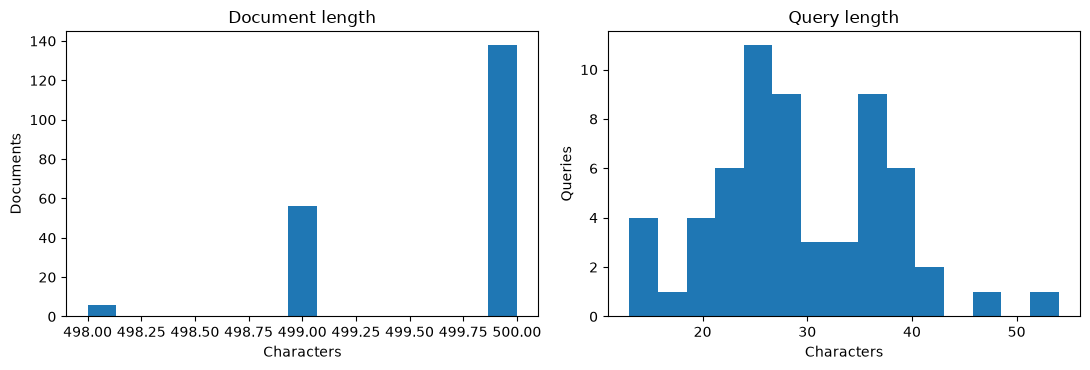

In [6]:
corpus_stats = corpus_df.copy()
valid_stats = valid_df.copy()
# ### 문서·질문의 글자 수를 계산하여 데이터 규모와 길이를 확인합니다.
corpus_stats['char_length'] = corpus_stats['text'].astype(str).str.len()
valid_stats['char_length'] = valid_stats['question'].astype(str).str.len()

print('문서 길이 통계:')
display(corpus_stats['char_length'].describe().to_frame('문서 글자 수'))
print('질문 길이 통계:')
display(valid_stats['char_length'].describe().to_frame('질문 글자 수'))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(corpus_stats['char_length'], bins=15)
axes[0].set(title='Document length', xlabel='Characters', ylabel='Documents')
axes[1].hist(valid_stats['char_length'], bins=15)
axes[1].set(title='Query length', xlabel='Characters', ylabel='Queries')
fig.tight_layout()
fig.savefig(FIGURES / 'cp01_length_distribution.png', dpi=140, bbox_inches='tight')
plt.show()

**질문–정답 문단 겹침 분석(공통).** TF-IDF는 질문과 문단에 같은 글자 묶음이 많이 나올수록 유리합니다. 질문의 글자 2개 묶음(2-gram) 가운데 정답 문단에도 나오는 비율을 질문마다 계산해 `valid_overlap`에 저장합니다. 겹침 비율이 낮은 질문은 문단과 다른 표현으로 물어본 질문입니다. 코드는 제공되며, 학생들은 표를 읽고 아래 기록을 작성합니다. 이 표는 CP-09에서 검색에 실패한 질문과 다시 비교합니다.

In [7]:
# [공통] CP-01 — 질문과 정답 문단의 글자 겹침 비율 (Validation 질문만 사용)
# 질문에 쓰인 글자가 정답 문단에도 얼마나 나오는가 

def char_bigrams(text):
    """어절 안에서 만든 글자 2개 묶음의 집합. 예: '검색 성능' → {'검색', '성능'}"""
    return {word[i:i + 2] for word in str(text).split() for i in range(len(word) - 1)}


def overlap_ratio(question, document):
    """질문의 글자 2-gram 중 문단에도 등장하는 비율(0~1)."""
    question_grams = char_bigrams(question)
    if not question_grams:
        return 0.0
    return len(question_grams & char_bigrams(document)) / len(question_grams)


_doc_text = corpus_df.set_index('doc_id')['text']
valid_overlap = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
valid_overlap['overlap'] = [overlap_ratio(q, _doc_text[d])
                            for q, d in zip(valid_overlap['question'], valid_overlap['relevant_doc_id'])]
print('질문–정답 문단 겹침 비율 통계:')
display(valid_overlap['overlap'].describe().to_frame('겹침 비율').round(3))
print('겹침 비율이 가장 낮은 질문 5개:')
display(valid_overlap.sort_values('overlap').head(5)[['query_id', 'question', 'overlap']].round(3))
valid_overlap.to_csv(TABLES / 'cp01_validation_overlap.csv', index=False, encoding='utf-8-sig')

질문–정답 문단 겹침 비율 통계:


,겹침 비율
count,60.000
mean,0.474
std,0.175
min,0.158
25%,0.333
50%,0.462
75%,0.601
max,0.882


겹침 비율이 가장 낮은 질문 5개:


,query_id,question,overlap
17,QV018,소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?,0.158
45,QV046,싸움에 대비한 체육을 다룬 교육의 명칭은?,0.167
51,QV052,한국전쟁은 남한이 일으켰다고 주장한 사람은?,0.200
50,QV051,누구나 쇼핑몰을 할 수 있게 된 것 같은 변화가 제조업에서도 일어날 수 있는 것은 ...,0.217
8,QV009,영국은 어느나라와의 싸움에서 승리해 코이누르 보석을 습득했나요?,0.227


In [8]:
low5 = valid_overlap.sort_values('overlap').head(5)      # 겹침이 가장 낮은 질문 5개
for row in low5.itertuples():
    print(row.query_id, '| 겹침', round(row.overlap, 3))
    print('질문:', row.question)
    print('정답 문단:', _doc_text[row.relevant_doc_id])   # 그 질문의 정답 문단 본문
    print('-' * 80)

QV018 | 겹침 0.158
질문: 소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?
정답 문단: ;현재의 세계
:마왕 헤트라슈바이켈 시대 이후 700년, 대륙은 수많은 국가가 전쟁을 벌이는 전국시대에 돌입한다. 이 혼란은 '천(天)의 여왕' 세라프 몰트 엘 크레이프의 등장과 함께 종식한다. 세계 유일의 황제가 된 세라프 몰트 엘 크레이프는 대륙 전체에 '마법금지정책'을 공표하게 된다.

;근대 소설
:한편, 문화의 시대가 된 현재에 염가판의 도서가 등장하고 서민들이 많은 책을 접하게 되면서 근대 소설의 시대가 열린다. '세레스 에레오르'라는 필명으로 쓴 '랑그라시아나의 밤'은 100만 부에 육박하는 판매 부수를 기록하는 큰 인기를 얻거나, 많은 양산형 문학이 등장하기도 한다. 본 작에서 서술되고 있는 근대 소설의 상황은 대한민국과 일본의 장르 문학의 현재 상황을 비유하고 있다.

;마장지
:대기 중의 마나가 고갈된 현재에 마법을 사용할 수 있는 수단으로, 이 종이에 마법식을 적어 마법을 사용할 수 있다. 마법금지정책으로 그 제조는 강력하게 규제되고 있다.

;카토르바슈 신성학원
--------------------------------------------------------------------------------
QV046 | 겹침 0.167
질문: 싸움에 대비한 체육을 다룬 교육의 명칭은?
정답 문단: 시민들이 서로 친분을 쌓았으며, 이는 굳건한 형제애를 형성하는 데에 도움이 된다.
* 시민들에게 자녀 부양 의무와 교육 의무를 부여했으며, 모든 시민의 자녀들에게 교육 혜택을 제공하였다. 교육은 생활 유지에 필수적인 사냥, 합리적 사고에 필수적인 논변학 및 수학과 전투에 도움이 되는 실전 체육이 주된 내용이었으며, 이를 아고게(agoge)라고 한다. 하지만, 장애가 있는 아이의 경우는 사회 효율성 증대에 도움이 되지 않는다는 이유로 죽이거나 내다 버리게 하였으며, 이 교육 과정에서 지향하는 과도한 경쟁성으로 인해 사망하는 아이들이 많

**[기록] 결과 해석 — CP-01**

- 문서 길이와 질문 길이 분포에서 관찰한 특징:
  문서 200개는 모두 498-500자다. 500자가 약 138개, 499자가 약 56개, 498자가 약 6개로, 데이터 준비 단계에서 지문을 500자로 잘랐기 때문에 길이가 사실상 같다. 따라서 문서 길이 차이가 검색 결과에 영향을 주지는 않는다. 질문은 13-54자이고 대부분 20-40자 사이에 있다. 문서가 질문보다 10배 이상 길어서, 문단 전체를 벡터 하나로 표현하면 질문이 묻는 한 문장의 내용이 희석될 수 있다.

- 질문–정답 문단 겹침 비율 분포에서 관찰한 특징:
  겹침 비율의 평균은 0.474, 중앙값은 0.462다. 질문에 쓰인 글자 묶음의 절반 이상이 정답 문단에 나오지 않으므로, 질문은 문단의 표현을 그대로 가져오지 않고 다른 말로 바꿔 쓴 경우가 많다. 최솟값 0.158부터 최댓값 0.882까지 넓게 퍼져 있어 질문마다 난이도 차이가 크다. 하위 25%(15개)는 0.333 이하이고 상위 25%(15개)는 0.601 이상이다. 겹침이 가장 낮은 질문은 QV018(0.158), QV046(0.167), QV052(0.200), QV051(0.217), QV009(0.227)이다. 정답 문단을 확인해 보니 질문이 문단의 표현을 다른 말로 바꿔 쓴 경우였다. 예를 들어 QV046은 문단의 "전투에 도움이 되는 실전 체육"을 "싸움에 대비한 체육"으로, QV052는 "6·25 동란"을 "한국전쟁"으로, QV009는 "전쟁에서 패한"을 "싸움에서 승리해"로 바꿔 물었다.

- 가설 1 — TF-IDF가 잘 찾을 것으로 예상하는 질문과 이유:
  겹침 비율이 0.6 이상인 상위 15개 질문은 TF-IDF가 정답 문단을 1위로 찾을 것으로 예상한다. TF-IDF는 같은 글자 묶음이 많을수록 유사도가 높아지기 때문이다. 겹침이 낮더라도 "코이누르", "한국전쟁"처럼 다른 문단에는 거의 나오지 않는 낱말이 겹치는 질문은 TF-IDF가 찾을 가능성이 있다.

- 가설 2 — BERT 기반 검색에서 유리하거나 불리할 것 같은 질문과 이유:
  겹침 비율이 0.333 이하인 하위 15개 질문은 TF-IDF가 놓치고, 의미를 반영하는 BERT 기반 검색이 더 잘 찾을 것으로 예상한다. 글자는 다르지만 뜻이 같은 표현을 연결할 수 있기 때문이다. 반대로 고유명사나 숫자처럼 글자가 정확히 일치해야 하는 질문에서는 BERT가 TF-IDF보다 불리할 수 있다. 또한 500자 문단을 벡터 하나로 평균하면 질문과 관련된 문장의 정보가 흐려질 수 있다는 점도 BERT에 불리한 요인이다.

**[CP-01 완료 기준]** 문서·질문 길이 통계와 그래프를 만들고 겹침 비율 표를 확인한 뒤, 두 검색 방식의 예상 강점·한계를 기록합니다. **Test 질문은 열지 않습니다.**


---
## CP-02. TF-IDF 기반 기준 검색기 구현

TF-IDF는 이미 배운 전통적인 텍스트 표현 방법입니다. 이번에는 한국어 띄어쓰기의 영향을 줄이기 위해 **문자 2~3-gram TF-IDF**를 기준선으로 사용하고, 질문과 문단 간 유사도로 Top-k를 찾습니다.


**TF-IDF 검색기(학생 구현).** 문서 전체의 벡터를 만든 뒤 질문을 같은 TF-IDF 기준으로 변환합니다. 코사인 유사도에 따라 점수를 정렬하고, 앞에서부터 k개의 문서를 반환합니다.


In [10]:
# [학생 구현] CP-02 — TF-IDF + 공통 Top-k 정렬 함수
from sklearn.feature_extraction.text import TfidfVectorizer      # 문서를 TF-IDF 벡터로 바꾸는 도구
from sklearn.metrics.pairwise import cosine_similarity           # 코사인 유사도를 계산하는 함수

# 글자 2~3개 묶음을 특징으로 쓰는 TF-IDF 변환기를 만듭니다. 묶음은 많이 나오는 3만 개까지만 씁니다.
tfidf_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 3), max_features=30000)

# 문서는 fit_transform입니다. 문서 200개에서 기준을 배우고(fit), 그 기준으로 벡터로 바꿉니다(transform).
tfidf_docs = tfidf_vectorizer.fit_transform(corpus_df['text'].astype(str).tolist())


def top_k_results(scores, frame, k=5):
    """유사도 배열 → 상위 k개 검색 결과 (rank, doc_id, score, text)."""
    # 점수를 한 줄짜리 실수 배열로 바꿉니다.
    scores = np.asarray(scores, dtype=np.float64).ravel()

    # 점수 개수와 문서 개수가 같은지 확인합니다. 다르면 여기서 멈춥니다.
    assert len(scores) == len(frame), '점수 길이와 문서 개수가 달라요.'

    # k가 1보다 작으면 1로, 문서 수보다 크면 문서 수로 맞춥니다.
    k = min(max(1, int(k)), len(frame))

    # 점수가 높은 순서대로 위치 번호 k개를 구합니다. 마이너스를 붙여야 큰 점수가 앞에 옵니다.
    order = np.argsort(-scores, kind='stable')[:k]

    # 위치 번호마다 순위(1부터), 문서 ID, 점수, 본문을 담은 딕셔너리를 만들어 리스트로 돌려줍니다.
    return [{'rank': rank, 'doc_id': str(frame.iloc[idx]['doc_id']),
             'score': float(scores[idx]), 'text': str(frame.iloc[idx]['text'])}
            for rank, idx in enumerate(order, start=1)]


def search_tfidf(query, k=5):
    ##### 중요! 질문은 transform만 합니다. 문서에서 배운 기준을 그대로 써야 문서 벡터와 비교할 수 있습니다.
    query_vector = tfidf_vectorizer.transform([str(query)])

    # 결과는 1행 200열짜리 표입니다. [0]으로 그 한 행을 꺼내면 문서 200개의 점수가 됩니다.
    scores = cosine_similarity(query_vector, tfidf_docs)[0]

    # 점수와 문서 표를 넘겨 상위 k개 결과를 돌려받습니다.
    return top_k_results(scores, corpus_df, k)


# TF-IDF 문서 행렬의 모양을 출력합니다. (문서 수, 글자 묶음 종류 수)입니다.
print('TF-IDF 문서 행렬 Shape:', tfidf_docs.shape)

# Validation 첫 번째 질문으로 상위 3개 문서를 검색합니다.
tfidf_demo = search_tfidf(valid_df.iloc[0]['question'], 3)

# 결과를 표로 보여 줍니다. 본문은 길어서 앞 90자만 표시합니다.
display(pd.DataFrame(tfidf_demo).assign(text=lambda x: x['text'].str.slice(0, 90)))

TF-IDF 문서 행렬 Shape: (200, 30000)


,rank,doc_id,score,text
0,1,D015,0.141820,"그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재..."
1,2,D078,0.069731,산업 혁명\n 산업혁명은 단순한 생산기술의 혁신에 의해서 발생한 생산성의 비약적 증...
2,3,D175,0.065917,마이클 베이 감독의 ‘트랜스포머:사라진 시대(사진)’가 중국에서 개봉한 영화 중 최...


**TF-IDF 검색 검증(공통).** 점수가 가장 큰 문서가 첫 번째 결과로 반환되어야 합니다. 검색 함수가 `rank·doc_id·score·text`를 모두 반환해야 BERT 검색과 같은 평가기를 재사용할 수 있습니다.


In [11]:
# [공통 검증] CP-02
_demo_corpus = pd.DataFrame({'doc_id': ['A', 'B', 'C'], 'text': ['가', '나', '다']})
_demo_rank = top_k_results([0.2, 0.9, 0.4], _demo_corpus, 2)
assert [h['doc_id'] for h in _demo_rank] == ['B', 'C']
assert list(_demo_rank[0]) == ['rank', 'doc_id', 'score', 'text']
assert tfidf_docs.shape[0] == len(corpus_df)
_check = search_tfidf(valid_df.iloc[0]['question'], 5)
assert len(_check) == 5 and len(set(h['doc_id'] for h in _check)) == 5
print('CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료')


CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료


**[CP-02 완료 기준]** TF-IDF 문서 행렬을 만들고 `search_tfidf(query, k)`가 유사도 내림차순의 결과를 반환하며 검증 셀을 통과합니다.


---
## CP-03. BERT Encoder 출력과 입력 Shape 분석

기존 KLUE-YNAT 뉴스 분류에서는 BERT 출력으로 분류했습니다. 이번에는 Classification Head가 아닌 BERT Encoder의 토큰별 문맥 벡터(`last_hidden_state`)를 문서 표현에 사용합니다.


**BERT 모델 로딩(공통).** `klue/bert-base`를 불러와 추론 모드로 전환합니다. 다운로드된 가중치는 `weights/`에 저장되므로 GPU 세션이 유지되는 동안 반복 다운로드하지 않습니다.


In [13]:
# [공통] CP-03 — BERT Encoder·Tokenizer 준비
from transformers import AutoTokenizer, AutoModel      # 토크나이저와 모델을 불러오는 도구

BASE_MODEL = 'klue/bert-base'     # 수업에서 쓴 한국어 BERT
MAX_LENGTH = 256                  # 한 문장에 넣을 최대 토큰 수. 넘으면 뒷부분을 자릅니다.
BATCH_SIZE = 16                   # 한 번에 처리할 문장 수

# 문장을 토큰 번호로 바꿔 주는 토크나이저를 불러옵니다. 파일은 weights 폴더에 저장됩니다.
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS))

# AutoModel은 분류기가 붙지 않은 BERT 본체(Encoder)만 불러옵니다.
bert_model = AutoModel.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS), use_safetensors=True)

# 모델을 GPU로 옮기고(to), 학습이 아닌 추론 상태로 바꿉니다(eval).
bert_model = bert_model.to(DEVICE).eval()

# 모델 이름과 벡터 크기를 출력합니다. klue/bert-base는 768입니다.
print('BERT Encoder:', BASE_MODEL, '| hidden_size:', bert_model.config.hidden_size)

BERT Encoder: klue/bert-base | hidden_size: 768


**BERT 입력·출력 구조 확인(학생 구현).** 서로 다른 길이의 질문 두 개를 Batch로 묶고 `attention_mask`와 `last_hidden_state`의 Shape를 확인합니다. 토큰마다 벡터가 하나씩 있으므로 아직 문장 하나당 벡터 하나인 상태가 아님을 확인하세요.


In [14]:
# [학생 구현] CP-03 — 토큰 단위 문맥 벡터 확인
# Validation 질문 중 앞의 2개를 문자열 리스트로 꺼냅니다.
sample_questions = valid_df['question'].head(2).astype(str).tolist()

# 질문 2개를 토큰 번호로 바꿉니다. padding=True는 짧은 문장 뒤를 [PAD]로 채워 두 문장의 길이를 맞춥니다.
inputs = tokenizer(sample_questions, padding=True, truncation=True,
                   max_length=MAX_LENGTH, return_tensors='pt')

# 입력 Tensor들을 모델과 같은 장치(GPU)로 옮깁니다. 장치가 다르면 오류가 납니다.
inputs = {key: value.to(DEVICE) for key, value in inputs.items()}

# 학습이 아니라 계산만 하므로, 기울기를 기록하지 않는 모드로 실행합니다.
with torch.inference_mode():
    # 딕셔너리를 풀어서 input_ids, attention_mask 등을 모델에 넣습니다.
    outputs = bert_model(**inputs)

    ##### 중요! 토큰마다 768차원 벡터가 하나씩 나옵니다. 모양은 (문장 수, 토큰 수, 768)입니다.
    last_hidden = outputs.last_hidden_state

# 실제 토큰은 1, [PAD]는 0으로 표시한 표입니다. CP-04에서 [PAD]를 평균에서 빼는 데 씁니다.
mask = inputs['attention_mask']

# 입력과 출력의 모양을 출력합니다.
print('input_ids:', tuple(inputs['input_ids'].shape))
print('attention_mask:', tuple(mask.shape))
print('last_hidden_state:', tuple(last_hidden.shape))

# 문장마다 1의 개수를 세어 [PAD]를 뺀 실제 토큰 수를 출력합니다.
print('유효 토큰 수:', mask.sum(dim=1).tolist())

# 출력의 (문장 수, 토큰 수)가 mask의 모양과 같은지 확인합니다.
assert last_hidden.shape[:2] == mask.shape

# 벡터 차원이 모델 설정값(768)과 같은지 확인합니다.
assert last_hidden.shape[-1] == bert_model.config.hidden_size


input_ids: (2, 19)
attention_mask: (2, 19)
last_hidden_state: (2, 19, 768)
유효 토큰 수: [15, 19]


**[기록] 결과 해석 — CP-03**

- `last_hidden_state`의 세 차원(Batch·Token·Hidden)이 각각 의미하는 것: 출력 Shape는 `(2, 19, 768)`이었다. 첫 번째 차원 2는 한 번에 넣은 질문의 개수(Batch)이다. 두 번째 차원 19는 문장 하나를 이루는 토큰 칸의 수이며, 두 질문 중 긴 쪽의 토큰 수에 맞춰졌다. 세 번째 차원 768은 토큰 하나를 표현하는 벡터의 크기(Hidden)이다. 즉 BERT는 문장마다 벡터 하나를 주는 것이 아니라 토큰마다 768차원 벡터를 하나씩 준다. 문장 하나에 벡터가 19개 있으므로, 문장끼리 비교하려면 이 토큰 벡터들을 하나의 문장 벡터로 합치는 과정이 따로 필요하다.
- `attention_mask`가 0인 위치를 평균에서 제외해야 하는 이유: 유효 토큰 수는 `[15, 19]`였다. 첫 번째 질문은 실제 토큰이 15개뿐이고, 나머지 4칸은 길이를 맞추려고 채운 `[PAD]`이다. `[PAD]` 위치에도 768차원 벡터가 나오지만 문장의 내용과 관계없는 값이다. 19칸을 그대로 평균 내면 이 4개의 벡터가 섞여 문장 벡터가 흐려진다. 또 같은 문장이라도 함께 묶인 문장의 길이에 따라 `[PAD]` 개수가 달라지므로, 문장 벡터가 Batch 구성에 따라 달라지는 문제도 생긴다. 그래서 `attention_mask`가 1인 위치의 벡터만 더하고, 실제 토큰 수로 나누어야 한다.

**[CP-03 완료 기준]** BERT Encoder 출력 Shape·Attention Mask를 직접 확인하고, 토큰 표현과 문장 표현의 차이를 기록합니다.


---
## CP-04. Attention Mask 기반 Mean Pooling 구현

BERT는 토큰마다 벡터 하나를 출력하지만 검색에서는 **질문 1개·문단 1개를 각각 하나의 벡터**로 표현해야 합니다. 패딩 위치를 제외하고 유효 토큰 벡터만 평균내는 함수를 구현합니다.


**Masked Mean Pooling(학생 구현).** Attention Mask를 `(B, T, 1)`로 바꾸어 토큰별 벡터에 곱합니다. 유효 토큰 벡터의 합을 유효 토큰 수로 나누되, 0으로 나누는 경우는 방지합니다.


In [15]:
# [학생 구현] CP-04 — Attention Mask 기반 Mean Pooling
def mean_pooling(last_hidden_state, attention_mask):
    """(B,T,H)+(B,T) → (B,H). 유효 토큰만 평균내는 함수."""
    # mask의 모양을 (2, 19)에서 (2, 19, 1)로 늘립니다. 그래야 (2, 19, 768)인 토큰 벡터와 곱할 수 있습니다.
    mask = attention_mask.unsqueeze(-1).to(last_hidden_state.dtype)

    ##### 중요! mask를 곱하면 [PAD] 벡터가 전부 0이 됩니다. 그다음 토큰 방향(dim=1)으로 더해 문장별 합계 (2, 768)을 만듭니다.
    masked_sum = (last_hidden_state * mask).sum(dim=1)

    # 문장별 실제 토큰 수를 셉니다. 모양은 (2, 1)이고, 0으로 나누지 않도록 아주 작은 값으로 하한을 둡니다.
    token_count = mask.sum(dim=1).clamp(min=1e-9)

    # 합계를 19가 아니라 실제 토큰 수로 나눕니다. 결과는 문장마다 768차원 벡터 하나입니다.
    return masked_sum / token_count


# CP-03에서 만든 토큰 벡터와 mask를 넣어 문장 벡터를 만듭니다.
sentence_vecs = mean_pooling(last_hidden, mask)

# Pooling 전후의 모양을 비교해서 출력합니다.
print('Pooling 전:', tuple(last_hidden.shape), '| Pooling 후:', tuple(sentence_vecs.shape))


Pooling 전: (2, 19, 768) | Pooling 후: (2, 768)


**Pooling 숫자 검증(공통).** 마지막 토큰에 매우 큰 숫자가 들어 있어도 `attention_mask=0`이면 평균에 포함되면 안 됩니다. 아래 검증 셀은 실제 BERT 가중치 없이 작은 Tensor만으로 정답을 확인합니다.


In [16]:
# [공통 검증] CP-04 — Padding을 제외한 평균
_toy_hidden = torch.tensor([[[1., 0.], [3., 2.], [100., 100.]],
                            [[2., 4.], [20., 20.], [40., 40.]]])
_toy_mask = torch.tensor([[1, 1, 0], [1, 0, 0]])
_toy_out = mean_pooling(_toy_hidden, _toy_mask)
assert _toy_out.shape == (2, 2)
assert torch.allclose(_toy_out, torch.tensor([[2., 1.], [2., 4.]]), atol=1e-6)
assert sentence_vecs.shape == (2, bert_model.config.hidden_size)
print('CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인')


CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인


**[CP-04 완료 기준]** `mean_pooling()`을 완성하고 유효 토큰만 평균을 낸 검증을 통과합니다. **생각해 볼 질문:** `attention_mask`를 무시하면 문장 길이에 따른 패딩이 검색 결과에 어떤 영향을 줄까요?


---
## CP-05. BERT 문서 임베딩과 코사인 유사도 계산

문서 200개를 BERT Encoder와 Pooling을 통과시켜 같은 차원의 벡터로 변환합니다. 질문 벡터와 각 문서 벡터의 **코사인 유사도**를 직접 계산합니다.


**BERT 임베딩 Batch 처리(학생 구현).** 문서를 한 번에 모두 처리하면 메모리를 많이 사용하므로 16개씩 Tokenizer → BERT → Mean Pooling을 반복합니다. 결과는 NumPy 배열로 합치며, 이후 GPU를 다시 사용하지 않도록 저장합니다.


In [19]:
# [학생 구현] CP-05 — BERT 임베딩 생성 함수
def encode_bert_texts(texts, batch_size=BATCH_SIZE):
    """문장/문단 리스트를 (N, Hidden) NumPy 배열로 반환."""
    # 입력을 모두 문자열로 바꿉니다.
    texts = [str(t) for t in texts]

    # 묶음마다 나온 문장 벡터를 모아 둘 빈 리스트입니다.
    vectors = []

    # 문서를 batch_size개씩 잘라서 처리합니다. 200개를 한꺼번에 넣으면 GPU 메모리가 부족할 수 있습니다.
    for start in range(0, len(texts), batch_size):
        # 이번 묶음에 해당하는 문장들을 꺼냅니다.
        batch = texts[start:start + batch_size]

        # CP-03과 같은 방법으로 묶음을 토큰 번호로 바꿉니다.
        encoded = tokenizer(batch, padding=True, truncation=True,
                            max_length=MAX_LENGTH, return_tensors='pt')

        # 입력 Tensor를 모델과 같은 장치로 옮깁니다.
        encoded = {key: value.to(DEVICE) for key, value in encoded.items()}

        # 기울기를 기록하지 않는 모드로 실행합니다.
        with torch.inference_mode():
            # BERT에 넣어 토큰 벡터 (묶음 크기, 토큰 수, 768)을 받습니다.
            hidden = bert_model(**encoded).last_hidden_state

            ##### 중요! CP-04에서 만든 함수로 토큰 벡터를 문장 벡터 (묶음 크기, 768)로 바꿉니다.
            pooled = mean_pooling(hidden, encoded['attention_mask'])

        # GPU에 있는 결과를 CPU로 가져와 NumPy 배열로 바꾼 뒤 리스트에 넣습니다.
        vectors.append(pooled.cpu().numpy())

    # 묶음별 결과를 세로로 이어 붙여 (문장 수, 768) 배열 하나로 만듭니다. 입력이 비어 있으면 빈 배열을 돌려줍니다.
    return np.vstack(vectors) if vectors else np.empty((0, bert_model.config.hidden_size))


def cosine_scores(query_vector, document_matrix):
    """질문 벡터 (H,)와 문서 행렬 (N,H)의 코사인 유사도 (N,)."""
    # 질문 벡터를 한 줄짜리 실수 배열 (768,)로 바꿉니다.
    query_vector = np.asarray(query_vector, dtype=np.float64).reshape(-1)

    # 문서 행렬을 실수 배열 (문서 수, 768)로 바꿉니다.
    document_matrix = np.asarray(document_matrix, dtype=np.float64)

    # 분자는 내적입니다. 문서 200개 각각과 질문 벡터를 곱해서 더한 값 200개가 나옵니다.
    numerator = document_matrix @ query_vector
    # (같은 것) numerator = np.matmul(document_matrix, query_vector)

    # 분모는 두 벡터 길이의 곱입니다. axis=1은 문서 한 줄마다 길이를 따로 구한다는 뜻입니다.
    denominator = np.linalg.norm(document_matrix, axis=1) * np.linalg.norm(query_vector)

    # 분자를 분모로 나눕니다. 분모가 0이 되지 않도록 아주 작은 값으로 하한을 둡니다.
    return numerator / np.maximum(denominator, 1e-12)


**문서 임베딩 캐싱(공통).** `bert_corpus_200_256.npy`가 이미 있으면 다시 계산하지 않습니다. 다만 저장된 벡터가 **지금의 `encode_bert_texts()`가 계산한 결과와 같은지** 앞 문서 4개로 먼저 확인합니다. 함수를 고친 뒤라서 결과가 다르면 전체를 다시 계산해 덮어쓰므로, 예전에 잘못 계산된 벡터가 계속 쓰이지 않습니다.

In [18]:
# [공통] CP-05 — BERT Corpus 임베딩 생성/재사용
# 문서 벡터를 저장할 파일 경로입니다. 이름의 200은 문서 수, 256은 최대 토큰 길이입니다.
BERT_DOC_CACHE = CACHE / 'bert_corpus_200_256.npy'


def load_or_encode(cache_file, texts, n_check=4):
    """저장된 임베딩이 현재 encode_bert_texts()의 결과와 같을 때만 재사용합니다."""
    # 입력을 모두 문자열로 바꿉니다.
    texts = [str(t) for t in texts]

    # 결과가 가져야 할 모양입니다. (문서 수, 768)이어야 합니다.
    expected_shape = (len(texts), bert_model.config.hidden_size)

    # 저장된 파일이 이미 있는지 확인합니다.
    if cache_file.is_file():
        # 파일에서 예전에 저장한 벡터를 읽어 옵니다.
        cached = np.load(cache_file)

        # 저장본의 모양이 (200, 768)인지 확인합니다.
        if cached.shape == expected_shape:
            # 앞의 문서 4개만 지금 함수로 다시 계산합니다. 저장본이 아직 쓸 만한지 확인하기 위한 검사입니다.
            fresh = encode_bert_texts(texts[:n_check])

            # 새로 계산한 4개와 저장본의 앞 4개가 같으면, 저장본을 그대로 돌려주고 함수를 끝냅니다.
            if fresh.shape == cached[:n_check].shape and np.allclose(fresh, cached[:n_check], atol=1e-3):
                print('저장된 임베딩 재사용:', cache_file.name)
                return cached

        # 여기까지 왔다면 저장본이 지금 함수의 결과와 다르다는 뜻이므로, 다시 계산한다고 알립니다.
        print('저장된 임베딩이 현재 함수의 결과와 달라 다시 계산합니다:', cache_file.name)

    # 파일이 없거나 저장본이 달랐을 때만 문서 200개 전체를 BERT로 계산합니다.
    vectors = encode_bert_texts(texts)

    # 계산한 벡터를 파일로 저장합니다.
    np.save(cache_file, vectors)

    # 계산한 벡터를 돌려줍니다.
    return vectors


# 문서 200개의 본문을 넣어 문서 벡터를 얻습니다. 이 변수는 CP-06 검색에서 그대로 씁니다.
bert_doc_vectors = load_or_encode(BERT_DOC_CACHE, corpus_df['text'].tolist())

# 문서 벡터의 모양을 출력합니다. (200, 768)이 나와야 합니다.
print('BERT 문서 벡터 Shape:', bert_doc_vectors.shape)

BERT 문서 벡터 Shape: (200, 768)


**코사인 유사도 검증(공통).** 질문과 같은 방향의 문서 벡터는 유사도가 1에 가까워야 합니다. 문서가 200개이므로 질문 하나에 대한 점수 배열도 반드시 길이 200이어야 합니다.


In [20]:
# [공통 검증] CP-05
_test_scores = cosine_scores(np.array([1., 0.]),
                             np.array([[1., 0.], [0., 1.], [-1., 0.]]))
assert np.allclose(_test_scores, [1., 0., -1.], atol=1e-6)
assert bert_doc_vectors.shape == (200, bert_model.config.hidden_size)
assert np.isfinite(bert_doc_vectors).all()
print('CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상')


CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상


**[CP-05 완료 기준]** BERT 임베딩 (200, 768) 배열을 저장하고, 직접 작성한 `cosine_scores()`가 숫자 검증을 통과합니다.


---
## CP-06. Top-k BERT 문서 검색기 완성

이제 질문을 같은 BERT Encoder로 벡터화하고 저장된 문서 벡터들과 비교합니다. CP-02에서 구현한 `top_k_results()`를 재사용해 **검색기가 하나의 완성된 프로그램**으로 동작하도록 연결합니다.


**BERT 검색 함수(학생 구현).** 질문 하나를 BERT 임베딩으로 변환해 문서 200개와 코사인 유사도를 계산합니다. 상위 k개 결과의 문서 ID, 유사도, 원문을 같은 인터페이스로 반환해야 Day 2에서 두 검색기를 공정하게 평가할 수 있습니다.


In [21]:
# [학생 구현] CP-06 — BERT 검색 함수
# 질문 문장을 키로, 그 질문의 벡터를 값으로 저장해 두는 사전입니다. 지금은 비어 있고 CP-07에서 채웁니다.
bert_query_cache = {}


def search_bert(query, k=5):
    # 질문을 문자열로 바꿉니다.
    query = str(query)

    # 사전에 이미 있는 질문이면 저장된 벡터를 꺼내 쓰고, 없으면 BERT로 새로 계산합니다.
    # [query]처럼 리스트로 감싸 넣었으므로 결과가 (1, 768)이고, [0]으로 한 줄 (768,)을 꺼냅니다.
    query_vector = (bert_query_cache[query] if query in bert_query_cache
                    else encode_bert_texts([query])[0])

    ##### 중요! 질문 벡터와 문서 벡터 200개의 코사인 유사도를 구합니다. 점수 200개가 나옵니다.
    scores = cosine_scores(query_vector, bert_doc_vectors)

    # CP-02에서 만든 정렬 함수를 그대로 다시 씁니다. TF-IDF와 같은 형식의 결과가 나옵니다.
    return top_k_results(scores, corpus_df, k)


# Validation 첫 번째 질문을 꺼냅니다. CP-02에서 TF-IDF로 검색했던 것과 같은 질문입니다.
_query = valid_df.iloc[0]['question']

# 질문을 출력합니다.
print('질문:', _query)

# 상위 3개 문서를 검색해 표로 보여 줍니다. 본문은 앞 90자만 표시합니다.
display(pd.DataFrame(search_bert(_query, 3)).assign(text=lambda x: x['text'].str.slice(0, 90)))



질문: 종교 개혁 전 영국에서 인기를 끌었던 헌신은?


,rank,doc_id,score,text
0,1,D015,0.693191,"그것이 표준이다. 다른 장면 세트와 마찬가지로, 그림, 아이보리 미니어처 조각, 재..."
1,2,D124,0.645154,아)로 떨어졌다. 많은 매체가 관련 기사를 내보냈는데 어느 정도 이런 추락을 예상했...
2,3,D068,0.640854,서양 근세의 교육은 14세기에서 17세기 초반 까지의 유럽 세계의 교육활동을 의미한...


**검색기 출력 검증(공통).** 두 검색 방식이 반환하는 항목과 순위 형식이 동일한지 확인합니다. 단위 테스트는 검색 결과의 구조만 확인하며, 이 단계에서 검색 점수가 높아야 한다는 조건을 요구하지 않습니다.


In [22]:
# [공통 검증] CP-06
_question = valid_df.iloc[0]['question']
for _search_fn in [search_tfidf, search_bert]:
    _hits = _search_fn(_question, 3)
    assert len(_hits) == 3 and [h['rank'] for h in _hits] == [1, 2, 3]
    assert all({'doc_id', 'text', 'score'} <= set(h) for h in _hits)
    assert _hits[0]['score'] >= _hits[1]['score'] >= _hits[2]['score']
print('CP-06 통과: TF-IDF / BERT Top-k 검색기 완성')


CP-06 통과: TF-IDF / BERT Top-k 검색기 완성


**[Day 1 완료 기준]** 문서 분석과 검색 성능 가설, TF-IDF 검색기, BERT Masked Mean Pooling, 코사인 유사도, `search_bert()`와 검증 셀을 모두 완료합니다. **Day 1 종료 후 작성한 Notebook을 GitHub에 저장하세요.**


# Day 2 — 검색 성능 평가·오류 분석·최종 검색 방식 선정

둘째 날은 `CP-07~10`을 진행합니다. **Validation 질문에서만 모델을 비교하고 선택**한 후, 보류 Test 질문은 CP-10의 최종 평가에 사용합니다.

---
## CP-07. 검색 평가 함수 구현 — Hit@1 · Recall@3 · MRR@5

분류에서 Accuracy·F1을 계산했던 것처럼 문서 검색에도 평가 기준이 필요합니다. 이번에는 질문마다 **정답 문서가 하나**이므로, 그 문서가 몇 위에 검색되었는지로 성능을 평가합니다.


**검색 평가 지표 구현(학생 구현).** Hit@1은 정답 문서가 첫 번째인지, Recall@3은 상위 3개에 있는지, MRR@5는 상위 5개 안에서의 정답 순위 역수입니다. 질문별 지표를 평균하여 전체 검색 성능을 계산합니다.


In [ ]:
# [학생 구현] CP-07 — 검색 평가 지표

def retrieval_metrics(hits, relevant_doc_id):
    """하나의 정답 문서 기준 Hit@1·Recall@3·MRR@5·rank 반환."""
    doc_ids = [h['doc_id'] for h in hits]
    # TODO 7-1. relevant_doc_id가 doc_ids에 있으면 순위(1부터 시작)를 구하세요. 없으면 None.
    # TODO 7-2. Hit@1, Recall@3, MRR@5를 각각 계산해
    #             {'hit1': ..., 'recall3': ..., 'mrr5': ..., 'rank': ...} 형태의 딕셔너리로 반환하세요.
    #             rank에는 7-1에서 구한 순위(없으면 None)를 넣습니다. CP-09에서 이 키 이름을 그대로 사용합니다.
    #             정답이 상위 5개에 없으면 MRR@5는 0입니다.
    raise NotImplementedError('CP-07 검색 평가 지표를 구현하세요.')


def evaluate_search(search_fn, questions_df):
    """질문 데이터 전체 검색 결과: (summary_dict, detail_DataFrame)."""
    rows = []
    for row in questions_df.itertuples(index=False):
        # TODO 7-3. search_fn(row.question, 5)를 호출하세요.
        # TODO 7-4. retrieval_metrics()로 정답 문서 순위·지표를 계산하세요.
        # TODO 7-5. query_id, question, relevant_doc_id, hit1, recall3, mrr5, rank, top1_doc_id를
        #           키로 가진 딕셔너리를 rows에 추가하세요.
        raise NotImplementedError('CP-07 평가 데이터셋 반복을 구현하세요.')
    detail = pd.DataFrame(rows)
    # TODO 7-6. hit1/recall3/mrr5 평균을 summary 딕셔너리로 만들고 (summary, detail)을 반환하세요.
    raise NotImplementedError('CP-07 전체 평균 지표를 계산하세요.')


**평가 지표 검증(공통).** 정답이 2위라면 Hit@1=0, Recall@3=1, MRR@5=0.5가 되어야 합니다. 먼저 작은 예제를 통과시킨 뒤 실제 Validation 질문 전체에 적용합니다.


In [ ]:
# [공통 검증] CP-07
_toy_hits = [{'doc_id': 'A'}, {'doc_id': 'B'}, {'doc_id': 'C'},
             {'doc_id': 'D'}, {'doc_id': 'E'}]
_m = retrieval_metrics(_toy_hits, 'B')
assert _m['hit1'] == 0 and _m['recall3'] == 1 and np.isclose(_m['mrr5'], 0.5)
assert retrieval_metrics(_toy_hits, 'A')['hit1'] == 1
assert retrieval_metrics(_toy_hits, 'Z')['mrr5'] == 0
print('CP-07 검색 지표 단위 테스트 통과')


**Validation 질문 임베딩 캐시(공통).** BERT 질문을 한 번에 Batch로 임베딩하여 CP-07~09의 반복 평가에서 재사용합니다. 캐시를 준비한 뒤 TF-IDF와 BERT의 실제 Validation 성능을 계산합니다.


In [ ]:
# [공통] CP-07 — 질문 벡터 일괄 계산 및 기준 성능 측정
BERT_VALID_CACHE = CACHE / 'bert_validation_60_256.npy'
# ### CP-05의 load_or_encode()로, 저장본이 현재 함수의 결과와 같을 때만 재사용합니다.
valid_bert_vecs = load_or_encode(BERT_VALID_CACHE, valid_df['question'].tolist())
bert_query_cache.update({str(q): vec for q, vec in
                         zip(valid_df['question'].tolist(), valid_bert_vecs)})

tfidf_summary, tfidf_detail = evaluate_search(search_tfidf, valid_df)
bert_summary, bert_detail = evaluate_search(search_bert, valid_df)
print('TF-IDF:', tfidf_summary)
print('BERT:', bert_summary)
assert len(tfidf_detail) == len(bert_detail) == len(valid_df)


**[CP-07 완료 기준]** 세 가지 지표의 단위 테스트를 통과하고, TF-IDF와 BERT의 Validation Hit@1·Recall@3·MRR@5를 계산합니다.


---
## CP-08. TF-IDF·BERT·Sentence-BERT 검색 성능 비교

일반 BERT의 Mean Pooling은 검색 작업에 맞춰 학습된 문장 임베딩과 다를 수 있습니다. 한국어 문장 유사도 모델을 추가하고 세 검색 방식의 실제 Validation 결과를 비교합니다.


**한국어 Sentence-BERT 준비(공통).** `snunlp/KR-SBERT-V40K-klueNLI-augSTS`를 이용해 문서 벡터를 생성합니다. 이미 계산한 문서·질문 임베딩이 있으면 저장된 `.npy` 파일을 사용하며, 별도의 Fine-tuning은 하지 않습니다.


In [ ]:
# [공통] CP-08 — Sentence-BERT 문서/질문 임베딩 준비
from sentence_transformers import SentenceTransformer

SBERT_MODEL = 'snunlp/KR-SBERT-V40K-klueNLI-augSTS'
sbert_model = SentenceTransformer(SBERT_MODEL, device=str(DEVICE), cache_folder=str(WEIGHTS))
# ### 기본 BERT와 비교할 때 문서가 잘리는 최대 토큰 길이를 통일합니다.
sbert_model.max_seq_length = MAX_LENGTH
SBERT_DOC_CACHE = CACHE / 'sbert_corpus_200.npy'
SBERT_VALID_CACHE = CACHE / 'sbert_validation_60.npy'

if SBERT_DOC_CACHE.is_file():
    sbert_doc_vectors = np.load(SBERT_DOC_CACHE)
else:
    sbert_doc_vectors = sbert_model.encode(corpus_df['text'].tolist(), batch_size=16,
                                            normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_DOC_CACHE, sbert_doc_vectors)
if SBERT_VALID_CACHE.is_file():
    sbert_valid_vectors = np.load(SBERT_VALID_CACHE)
else:
    sbert_valid_vectors = sbert_model.encode(valid_df['question'].tolist(), batch_size=16,
                                              normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_VALID_CACHE, sbert_valid_vectors)
assert len(sbert_doc_vectors) == len(corpus_df)
assert len(sbert_valid_vectors) == len(valid_df)
sbert_query_cache = {str(q): v for q, v in zip(valid_df['question'], sbert_valid_vectors)}
print('SBERT 문서 벡터:', sbert_doc_vectors.shape)


**세 가지 검색 방식 비교(학생 구현).** Sentence-BERT 검색 함수를 작성하고 앞에서 만든 `evaluate_search()`로 동일한 Validation 질문을 평가합니다. 세 방식의 지표를 하나의 DataFrame과 막대그래프로 정리하세요.


In [ ]:
# [학생 구현] CP-08 — Sentence-BERT 검색 + 성능 비교

def search_sbert(query, k=5):
    query = str(query)
    # TODO 8-1. sbert_query_cache에 query가 있으면 캐시를, 없으면 sbert_model.encode()를 사용하세요.
    # TODO 8-2. 질문 벡터와 sbert_doc_vectors의 코사인 유사도를 계산하고 top_k_results()로 검색 결과를 반환하세요.
    raise NotImplementedError('CP-08 SBERT 검색을 구현하세요.')

# TODO 8-3. evaluate_search(search_sbert, valid_df)로 SBERT Validation을 평가하고
#           결과를 sbert_summary, sbert_detail이라는 이름으로 받으세요.
# TODO 8-4. tfidf_summary, bert_summary, sbert_summary를 comparison_df로 만드세요.
#             행: tfidf, bert, sbert / 열: hit1, recall3, mrr5
# TODO 8-5. comparison_df를 cp08_validation_comparison.csv로 저장하고 막대그래프를 그리세요.
raise NotImplementedError('CP-08 세 검색 방식의 성능을 비교하세요.')


**비교 결과 검증(공통).** 세 검색기의 검색 결과 형식이 같고 지표가 0~1 사이인지 확인합니다. 성능의 순위는 데이터에 따라 달라지므로 BERT나 Sentence-BERT가 무조건 높아야 한다는 조건은 없습니다.


In [ ]:
# [공통 검증] CP-08
assert comparison_df.index.tolist() == ['tfidf', 'bert', 'sbert']
assert (comparison_df[['hit1', 'recall3', 'mrr5']] >= 0).all().all()
assert (comparison_df[['hit1', 'recall3', 'mrr5']] <= 1).all().all()
assert len(sbert_detail) == len(valid_df)
assert search_sbert(valid_df.iloc[0]['question'], 3)[0]['rank'] == 1
print('CP-08 통과: 세 검색 방식의 Validation 평가 완료')


**[기록] 결과 해석 — CP-08**

- 세 검색기의 Hit@1·Recall@3·MRR@5 차이: **[실제 수치와 함께 작성]**
- 예상과 다른 결과가 있다면 가능 원인: **[직접 작성]**

**[CP-08 완료 기준]** 세 방식의 동일 Validation 질문 비교표·그래프와 결과 해석을 완성합니다.


---
## CP-09. 검색 실패 사례 분석 및 최종 검색 방식 선정

성능 지표가 비슷하더라도 어떤 질문을 잘 찾고, 어떤 질문에서 실패하는지는 다를 수 있습니다. CP-01에서 세운 가설을 실제 Validation 검색 오류와 비교한 뒤 활용 목적에 맞는 검색 방식을 직접 선택합니다.


**검색 실패 질의 분석(학생 구현).** 세 검색기의 질문별 Hit@1을 합쳐 실패한 질문을 5개 이상 선정합니다. 세 검색기의 상위 문서와 정답 문서 ID를 나란히 비교하고 오류 원인을 기록합니다.


In [ ]:
# [학생 구현] CP-09 — 질문별 성공/실패 비교 및 대표 오류 선택
error_df = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
# TODO 9-1. tfidf_detail, bert_detail, sbert_detail을 query_id로 병합하세요.
#             각 모델의 hit1/recall3/rank에는 모델 이름 접두사를 붙이세요.
# TODO 9-2. num_top1_failures = 3 - 세 모델의 hit1 합계를 계산하세요.
# TODO 9-3. 실패가 많은 질문 상위 5개를 error_cases로 추출해 표로 출력하세요.
# TODO 9-4. 질문 하나에 대한 세 검색기의 Top-3 doc_id·유사도를 출력하세요.
# TODO 9-5. error_cases를 TABLES/'cp09_error_cases.csv'에 저장하세요.
# [힌트] CP-01의 valid_overlap[['query_id', 'overlap']]을 query_id로 병합해 두면
#        실패한 질문의 겹침 비율을 함께 볼 수 있습니다.
raise NotImplementedError('CP-09 검색 실패 사례를 비교하세요.')


**[기록] 결과 해석 — CP-09**

- 대표 실패 질문 5개에서 확인한 원인 (표면 단어 불일치, 문서 길이, 의미 혼동 등): **[직접 작성]**
- 실패한 질문의 겹침 비율(CP-01)은 전체 평균과 비교해 어떤가? 겹침이 낮은 질문은 어느 검색기가 더 잘 찾았는가?: **[직접 작성]**
- CP-01에서 예상한 TF-IDF/BERT의 장단점이 실제로 확인되었는가?: **[직접 작성]**
- 어떤 질문 유형에서 최종 검색기가 특히 좋은/나쁜 결과를 보이는가?: **[직접 작성]**


**최종 검색 방식 선정(학생 구현).** 실제 활용 목적과 가장 중요한 검색 지표를 정의한 후 Validation 결과에 근거해 검색 방식을 선택합니다. 선택값·대안·트레이드오프를 JSON으로 저장하면 최종 ADR의 근거로 활용할 수 있습니다.


In [ ]:
# [학생 구현] CP-09 — 사용 목적 및 선택 근거
# TODO 9-6. 검색기를 사용할 실제 상황을 USE_CASE로 한 문장 작성하세요.
# TODO 9-7. PRIORITY_METRIC을 'hit1', 'recall3', 'mrr5' 중 하나로 지정하세요.
# TODO 9-8. comparison_df의 Validation 점수와 오류 사례를 고려하여
#             SELECTED_METHOD를 'tfidf', 'bert', 'sbert' 중 하나로 직접 선택하세요.
# TODO 9-9. SELECTION_REASON에 실제 수치와 다른 방법의 장단점을 2~3문장으로 적으세요.
raise NotImplementedError('CP-09 최종 검색 방식·판단 근거를 지정하세요.')

assert PRIORITY_METRIC in ('hit1', 'recall3', 'mrr5')
assert SELECTED_METHOD in ('tfidf', 'bert', 'sbert')
selection = {'use_case': USE_CASE, 'priority_metric': PRIORITY_METRIC,
             'selected_method': SELECTED_METHOD, 'selection_reason': SELECTION_REASON,
             'validation_metrics': comparison_df.reset_index().to_dict('records')}
(REPORTS / 'cp09_selection.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('선정 모델:', SELECTED_METHOD, '| 우선 지표:', PRIORITY_METRIC)


**[CP-09 완료 기준]** 검색 실패 질문 5건을 분석하고, CP-01의 가설을 검증합니다. 사용 목적·우선 지표·선택 검색기·근거를 기록한 `cp09_selection.json`을 저장합니다.


---
## CP-10. 최종 `search_docs()` 완성 및 보류 Test 검증

CP-09에서 선택한 검색 방식을 하나의 사용자 함수 `search_docs()`로 연결합니다. **선택한 방법은 Test 결과를 확인한 뒤 바꾸지 않으며**, 새로운 질문에서도 최종 검색기가 동작하는지 확인합니다.


**최종 검색 함수(학생 구현).** 저장된 선택값에 맞춰 TF-IDF/BERT/Sentence-BERT 함수를 호출하고 Top-k 문서를 반환합니다. 이후 처음으로 Test 질문을 읽어 별도 데이터에서의 최종 성능을 검증합니다.


In [ ]:
# [학생 구현] CP-10 — 최종 검색기 인터페이스

def search_docs(query, k=3, method=SELECTED_METHOD):
    """선택한 검색 방식의 상위 k개 문서 반환."""
    # TODO 10-1. method가 'tfidf'라면 search_tfidf(), 'bert'라면 search_bert(),
    #              'sbert'라면 search_sbert()를 호출하도록 작성하세요.
    # TODO 10-2. 세 방법 모두 동일한 rank/doc_id/score/text 구조로 반환하세요.
    raise NotImplementedError('CP-10 최종 search_docs()를 구현하세요.')

# TODO 10-3. 본인이 만든 새로운 질문 한 개로 search_docs() Top-3를 확인하세요.


**보류 Test 평가·저장(학생 구현).** CP-09의 선택을 고정한 채 Test 질문 20개를 처음으로 평가합니다. Validation과 Test의 성능 차이 및 데이터 한계를 기록하고 CSV·JSON 결과를 출력합니다.


In [ ]:
# [학생 구현] CP-10 — 보류 Test 최종 평가 (이 셀에서 Test 정답을 처음 사용)
test_df = pd.read_csv(TEST_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(test_df) == 20
# TODO 10-4. SELECTED_METHOD를 바꾸지 않고 search_docs()로 Test 질문 20개를 평가하고
#            결과를 test_summary, test_detail이라는 이름으로 받으세요.
# TODO 10-5. comparison_df의 선택 모델 Validation 점수와 Test 점수를 final_compare라는 DataFrame으로
#            정리하세요. 행은 Validation, Test 두 개입니다.
# TODO 10-6. final_compare는 TABLES / 'cp10_validation_test_comparison.csv'로,
#            test_detail은 TABLES / 'cp10_test_query_results.csv'로 저장하세요.
# TODO 10-7. 선택 방법, 우선 지표, Validation·Test 점수를 REPORTS / 'cp10_final_report.json'에 저장하세요.
# [주의] 검증 셀이 위 변수 이름과 파일 이름을 그대로 확인합니다.
raise NotImplementedError('CP-10 최종 Test 평가 및 CSV/JSON 저장을 완성하세요.')


**최종 프로젝트 검증(공통).** Test 데이터는 더 이상 모델 선택에 사용하지 않습니다. 두 분할의 성능표와 JSON을 저장했는지 확인하고, 최종 검색 함수가 사용자가 입력한 질문에서 정상 동작하는지 점검합니다.


In [ ]:
# [공통 검증] CP-10
assert len(test_detail) == 20
assert len(final_compare) == 2
assert all((TABLES / n).is_file() for n in ['cp10_validation_test_comparison.csv', 'cp10_test_query_results.csv'])
assert (REPORTS / 'cp10_final_report.json').is_file()
assert search_docs('이 기사에서 설명하는 현상은 무엇인가요?', 3)[0]['rank'] == 1
print('CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료')


**[기록] 결과 해석 — CP-10**

- 최종 선택 모델의 Validation 및 Test 지표 차이: **[실제 수치 작성]**
- 검색에 실패한 Test 질문의 특징과 예상 원인: **[직접 작성]**
- 이 작은 KLUE-MRC 변환 데이터로 실제 업무 검색 품질을 보장할 수 없는 이유: **[직접 작성]**

### CP-10 종료 후 — 프로젝트 문서 작성 (별도 제출, 체크포인트에 포함되지 않음)

1. **프로젝트 명세서:** 입력·출력, 데이터셋, 세 검색기의 역할과 주요 함수
2. **ADR:** USE_CASE, PRIORITY_METRIC, SELECTED_METHOD, SELECTION_REASON 및 비교한 대안
3. **결과 분석 문서:** CP-01 가설, CP-08 비교표, CP-09 실패 사례, CP-10 Test 평가·한계

**[최종 완료 기준]** CP-01~10 구현·검증, 선택 근거 기록, 보류 Test 평가, 필수 문서 작성 후 Notebook을 GitHub에 Push합니다. 다운로드한 원본 문서·대형 모델 가중치는 GitHub에 올리지 않습니다.
